# MVP — Análise de Dados e Boas Práticas

**Título do projeto:** O Rio de Janeiro como porta de entrada do turismo internacional (2023–2025)

**Nome:** Silvia Rangel Lopes

**Matrícula:**4052026000651

**Dataset:** Chegadas de Turistas Internacionais — Ministério do Turismo(https://dados.turismo.gov.br/dataset/chegada-de-turistas-internacionais)

**Versão entregue:** 1.0

**Google Colab:** https://colab.research.google.com/drive/1cM8nK034Gwz8gJMxH9Yv8cRCgNP090W7?usp=sharing

# 1. Problema e perguntas

## 1.1 Contexto e objetivo

Os fluxos de turistas internacionais podem variar ao longo do ano conforme o país de residência e a via de entrada. Entender essas variações ajuda a identificar os meses de maior movimento e os mercados que mais contribuem para esse fluxo, informações úteis para o planejamento turístico.

Este trabalho tem como objetivo descrever as chegadas de turistas internacionais ao Brasil pelo estado do Rio de Janeiro, de janeiro de 2023 a dezembro de 2025, com dados do Ministério do Turismo. Na base preparada para a análise, cada linha representará uma combinação de ano, mês, país de residência e via de entrada, com o respectivo total de chegadas.

## 1.2 Perguntas ou hipóteses

- **H1:**  Quais meses concentram o maior volume de chegadas internacionais pelo Rio de Janeiro em cada ano, e quais países de residência mais contribuem para esses picos? O padrão se repete de 2023 a 2025?
- **H2:** Em um mesmo mês e ano, como a participação dos países de residência varia entre as chegadas por via aérea e por via marítima?

O recorte considera o estado do Rio de Janeiro como porta de entrada no Brasil. A medida analisada é o número de chegadas registradas. O destino final da viagem e a contagem de pessoas únicas ficam fora do alcance da base.

# 2. Fonte e significado dos dados

## 2.1 Proveniência e acesso

Os dados foram publicados pelo Ministério do Turismo no conjunto [Chegadas de Turistas Internacionais](https://dados.turismo.gov.br/dataset/chegada-de-turistas-internacionais). A fonte original são os registros administrativos de migração coletados pela Polícia Federal nos pontos de entrada do Brasil. O portal informa que os arquivos são disponibilizados sob a licença Open Data Commons Open Database License (ODbL).

| Ano de referência | Recurso oficial | Arquivo | Última atualização indicada no portal |
|---|---|---|---|
| 2023 | [Recurso de 2023](https://dados.turismo.gov.br/dataset/chegada-de-turistas-internacionais/resource/24761490-6668-4a55-84a6-994d0e9cf84d) | `chegadas_2023.csv` | 16/04/2024 |
| 2024 | [Recurso de 2024](https://dados.turismo.gov.br/dataset/chegada-de-turistas-internacionais/resource/a1336a87-2458-4034-bc13-fb4e3523db2f) | `chegadas_2024.csv` | 06/02/2025 |
| 2025 | [Recurso de 2025](https://dados.turismo.gov.br/dataset/chegada-de-turistas-internacionais/resource/53dd37d0-42fe-4c23-9a9a-8248191d06e8) | `chegadas-2025.csv` | 05/02/2026 |

Os arquivos têm cobertura nacional. O recorte deste trabalho vai de janeiro de 2023 a dezembro de 2025 e seleciona os registros em que `UF` é igual a `Rio de Janeiro`. Esse campo identifica o estado de entrada no Brasil.

## 2.2 Dicionário das variáveis

| Variável | Significado | Tipo | Unidade ou categorias | Observações e valores de ausência |
|---|---|---|---|---|
| `uf_entrada` | Unidade da Federação pela qual ocorreu a entrada no Brasil | Texto categórico | Unidades da Federação | Campo original `UF`. Usado para selecionar o Rio de Janeiro. |
| `ano` | Ano da chegada | Inteiro | 2023, 2024 ou 2025 | Campo original `ano`. |
| `mes` | Mês da chegada | Inteiro ordinal | 1 a 12 | Campo `Mês` em 2023 e 2024 e `mes` em 2025. Os nomes dos meses serão convertidos para números. |
| `pais_residencia` | País de residência permanente do turista | Texto categórico | Países ou agrupamentos publicados pela fonte | Campo `País` em 2023 e 2024 e `nome_pais_correto` em 2025. |
| `via_entrada` | Via pela qual ocorreu a entrada no Brasil | Texto categórico | Aérea, terrestre, marítima ou fluvial na base nacional | Campo `Via` em 2023 e 2024 e `Via_de_acesso` em 2025. As grafias serão padronizadas. |
| `chegadas` | Quantidade de chegadas registrada | Inteiro | Número de chegadas | Campo original `Chegadas`. Um zero explícito será tratado como contagem zero. Campos vazios serão verificados no diagnóstico. |

# 3. Ambiente e carregamento

 O pandas será usado para ler os arquivos CSV, o Path para localizar os arquivos na sessão do Colab e o display para exibir as tabelas no notebook. A saída da célula registra as versões do Python e do pandas para documentar o ambiente de execução e facilitar a reprodução do trabalho.

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)

Python: 3.13.18
pandas: 2.2.3


In [2]:
url_base = "https://raw.githubusercontent.com/Silvinharl/MVP_Analise_de_dados/main/dados"

arquivos = {
    2023: "chegadas_2023.csv",
    2024: "chegadas_2024.csv",
    2025: "chegadas-2025.csv",
}

dados_originais = {}

for ano, nome_arquivo in arquivos.items():
    dados = pd.read_csv(
        f"{url_base}/{nome_arquivo}",
        sep=";",
        encoding="iso-8859-1",
        dtype="string",
        keep_default_na=False,
    )
    dados_originais[ano] = dados

    linhas, colunas = dados.shape
    print(f"{ano} | {linhas:,} linhas × {colunas} colunas")
    display(dados.head(3))

2023 | 34,764 linhas × 12 colunas


,Continente,cod continente,País,cod pais,UF,cod uf,Via,cod via,ano,Mês,cod mes,Chegadas
0,América do Sul,4,Peru,34,Acre,1,Aéreo,1,2023,Novembro,11,0
1,América do Sul,4,Peru,34,Acre,1,Aéreo,1,2023,Novembro,11,0
2,Ásia,5,Outros países,56,Outras Unidades da Federação,99,Aéreo,1,2023,Junho,6,0


2024 | 22,856 linhas × 12 colunas


,Continente,cod continente,País,cod pais,UF,cod uf,Via,cod via,ano,Mês,cod mes,Chegadas
0,Europa,6,Alemanha,57,Outras Unidades da Federação,99,Aérea,1,2024,Janeiro,1,10
1,América do Sul,4,Argentina,26,Outras Unidades da Federação,99,Aérea,1,2024,Janeiro,1,1197
2,Europa,6,Bélgica,59,Outras Unidades da Federação,99,Aérea,1,2024,Janeiro,1,3


2025 | 24,800 linhas × 6 colunas


,Via_de_acesso,UF,nome_pais_correto,mes,ano,Chegadas
0,Aérea,Rio de Janeiro,Afeganistão,Janeiro,2025,1
1,Aérea,São Paulo,Afeganistão,Janeiro,2025,3
2,Terrestre,Paraná,Afeganistão,Janeiro,2025,2


Os três arquivos CSV foram lidos diretamente da pasta dados/ do repositório público do MVP, usando os links Raw do GitHub. A leitura foi feita com pandas, com ponto e vírgula como separador e codificação ISO-8859-1. Os valores foram lidos como texto para preservar a grafia original, os códigos e os campos vazios para a etapa de diagnóstico. Cada arquivo foi armazenado separadamente por ano no dicionário `dados_originais`.

Para conferir a leitura, foram exibidas as dimensões e as três primeiras linhas de cada arquivo. A base nacional contém 34.764 linhas e 12 colunas em 2023, 22.856 linhas e 12 colunas em 2024 e 24.800 linhas e 6 colunas em 2025. A diferença na estrutura de 2025 será tratada na padronização das colunas.

# 4. Análise exploratória

## 4.1 Dimensões, tipos e qualidade

Antes de selecionar os registros do Rio de Janeiro, foram verificadas as grafias e as frequências dos valores da coluna `UF` nos três arquivos nacionais. Nos arquivos de 2023 e 2024, a seleção pelo nome da UF também foi comparada com a seleção pelo código correspondente. O arquivo de 2025 traz apenas o nome da UF, por isso a verificação desse ano se baseia na revisão dos rótulos presentes no arquivo.

In [3]:
# Exibe os rótulos originais e quantas vezes aparecem em cada arquivo.
frequencias_uf = pd.concat(
    {
        ano: dados["UF"].map(repr).value_counts()
        for ano, dados in dados_originais.items()
    },
    axis=1,
).fillna(0).astype(int).sort_index()

display(frequencias_uf)

# Confere se o nome e o código selecionam as mesmas linhas.
for ano in (2023, 2024):
    dados = dados_originais[ano]
    nome_rj = dados["UF"].str.strip().eq("Rio de Janeiro")
    codigo_uf = dados["cod uf"].str.strip()
    codigos_rj = codigo_uf.loc[nome_rj & codigo_uf.ne("")].unique()

    if len(codigos_rj) != 1:
        print(f"{ano} | Códigos associados ao RJ para revisar: {list(codigos_rj)}")
        continue

    codigo_rj = codigo_uf.eq(codigos_rj[0])
    divergencias = dados.loc[nome_rj.ne(codigo_rj), ["UF", "cod uf"]]

    print(f"{ano} | Código do RJ: {codigos_rj[0]} | Divergências: {len(divergencias)}")
    if not divergencias.empty:
        display(divergencias.value_counts().rename("linhas").reset_index())

,2023,2024,2025
UF,,,
'Acre',832,415,469
'Alagoas',0,0,245
'Amapá',1222,651,674
'Amazonas',1552,1084,1181
'Bahia',1853,1050,1390
'Ceará',1440,954,1021
'Distrito Federal',1417,1042,1110
'Espírito Santo',0,0,10
'Goiás',0,0,19


2023 | Código do RJ: 19 | Divergências: 0
2024 | Código do RJ: 19 | Divergências: 0


Nos arquivos de 2023 e 2024, a seleção pelo nome `Rio de Janeiro` coincidiu com a seleção pelo código `19`, com zero divergências entre as linhas selecionadas. Em 2025, a inspeção dos rótulos da coluna `UF` não identificou grafias alternativas para o estado. Com base nessas verificações, foi adotada a igualdade com `Rio de Janeiro` após a remoção de espaços nas extremidades do campo. Em 2025, a verificação se limita aos rótulos informados pela fonte.

In [4]:
dados_rj = {}

for ano, dados in dados_originais.items():
    filtro_rj = dados["UF"].str.strip().eq("Rio de Janeiro")
    dados_rj[ano] = dados.loc[filtro_rj].copy()

    print(f"{ano} | {len(dados_rj[ano])} linhas do RJ")

total_rj = sum(len(dados) for dados in dados_rj.values())
print(f"Total | {total_rj} linhas do RJ")

2023 | 3140 linhas do RJ
2024 | 2349 linhas do RJ
2025 | 2407 linhas do RJ
Total | 7896 linhas do RJ


Para aplicar o recorte geográfico, foram removidos os espaços no início e no fim dos valores da coluna `UF`. Em seguida, foram selecionadas as linhas em que essa coluna é igual a `Rio de Janeiro`, que identifica o estado de entrada no Brasil. Os recortes foram armazenados por ano no dicionário `dados_rj`, preservando as tabelas carregadas em `dados_originais`.

O filtro selecionou **3.140 linhas em 2023**, **2.349 em 2024** e **2.407 em 2025**, totalizando **7.896 linhas**. O volume de chegadas será calculado a partir da coluna `Chegadas`.

In [5]:
for ano, dados in dados_rj.items():
    vazios_por_coluna = dados.apply(
        lambda coluna: coluna.fillna("").str.strip().eq("").sum()
    )
    repetidas = dados.duplicated().sum()

    print(f"{ano} | Campos vazios: {vazios_por_coluna.sum()}")
    print(f"{ano} | Linhas idênticas além da primeira: {repetidas}")

    colunas_com_vazios = vazios_por_coluna[vazios_por_coluna.gt(0)]
    if not colunas_com_vazios.empty:
        display(colunas_com_vazios.rename("Campos vazios").to_frame())

2023 | Campos vazios: 0
2023 | Linhas idênticas além da primeira: 779
2024 | Campos vazios: 0
2024 | Linhas idênticas além da primeira: 363
2025 | Campos vazios: 0
2025 | Linhas idênticas além da primeira: 5


A checagem do recorte do Rio de Janeiro encontrou zero campos vazios ou preenchidos apenas com espaços nos três anos. Foram identificadas 779 ocorrências adicionais de linhas idênticas em 2023, 363 em 2024 e 5 em 2025. Para avaliar se cabe remover essas linhas, será medido o efeito da exclusão sobre o total anual de chegadas.

In [6]:
for ano, dados in dados_rj.items():
    chegadas = dados["Chegadas"].str.strip()
    formato_valido = chegadas.str.fullmatch(r"[0-9]+", na=False)
    valores = pd.to_numeric(chegadas[formato_valido])

    print(f"{ano} | Valores fora do formato esperado: {(~formato_valido).sum()}")
    print(f"{ano} | Linhas com zero chegadas: {valores.eq(0).sum()}")

    if (~formato_valido).any():
        display(chegadas[~formato_valido].value_counts(dropna=False))

2023 | Valores fora do formato esperado: 0
2023 | Linhas com zero chegadas: 977
2024 | Valores fora do formato esperado: 0
2024 | Linhas com zero chegadas: 0
2025 | Valores fora do formato esperado: 0
2025 | Linhas com zero chegadas: 0


A coluna `Chegadas` apresentou apenas valores no formato de inteiro não negativo nos três anos. Em 2023, 977 das 3.140 linhas do recorte do Rio de Janeiro registraram zero chegadas, o equivalente a 31,1% das linhas. Em 2024 e 2025, nenhuma linha apresentou zero explícito. Essa verificação descreve os valores presentes nos arquivos. O significado das combinações que não aparecem em cada ano permanece em aberto.

In [7]:
resumo_repeticoes = []

for ano, dados in dados_rj.items():
    linhas_repetidas = dados.duplicated()
    chegadas_repetidas = pd.to_numeric(
        dados.loc[linhas_repetidas, "Chegadas"].str.strip()
    )

    resumo_repeticoes.append({
        "Ano": ano,
        "Linhas idênticas além da primeira": linhas_repetidas.sum(),
        "Com zero chegadas": chegadas_repetidas.eq(0).sum(),
        "Com chegadas positivas": chegadas_repetidas.gt(0).sum(),
    })

display(pd.DataFrame(resumo_repeticoes).set_index("Ano"))

,Linhas idênticas além da primeira,Com zero chegadas,Com chegadas positivas
Ano,,,
2023,779,473,306
2024,363,0,363
2025,5,0,5


Em 2023, das 779 ocorrências adicionais de linhas idênticas, 473 registraram zero chegadas e 306 apresentaram valores positivos. Em 2024 e 2025, todas as ocorrências adicionais tinham valores positivos, com 363 e 5 linhas, respectivamente. Como excluir essas ocorrências altera a soma de chegadas, foram comparados os totais anuais com todas as linhas e mantendo apenas a primeira ocorrência de cada linha idêntica.

In [8]:
comparacao_totais = []

for ano, dados in dados_rj.items():
    chegadas = pd.to_numeric(dados["Chegadas"].str.strip())
    linhas_repetidas = dados.duplicated()

    total_original = chegadas.sum()
    total_sem_repeticoes = chegadas.loc[~linhas_repetidas].sum()

    comparacao_totais.append({
        "Ano": ano,
        "Total com todas as linhas": total_original,
        "Total sem repetições idênticas": total_sem_repeticoes,
        "Redução no total": total_original - total_sem_repeticoes,
    })

display(pd.DataFrame(comparacao_totais).set_index("Ano"))

,Total com todas as linhas,Total sem repetições idênticas,Redução no total
Ano,,,
2023,1192814,1192131,683
2024,1528133,1527196,937
2025,2196443,2196424,19


Para avaliar o efeito das linhas idênticas, comparei a soma anual de `Chegadas` em dois cenários: com todas as linhas do recorte do Rio de Janeiro e mantendo apenas a primeira ocorrência de cada linha idêntica. A exclusão das ocorrências adicionais reduziu o total em 683 chegadas em 2023, 937 em 2024 e 19 em 2025.

Como a soma com todas as linhas coincidiu com os totais oficiais nos três anos, optei por manter as linhas conforme publicadas. Essa conferência sustenta a decisão no nível dos totais anuais. A origem das repetições permanece em aberto. [Ministério do Turismo — 2023 e 2024](https://www.gov.br/turismo/pt-br/anuario-estatistico-2025.pdf/) · [Embratur — 2025](https://embratur.com.br/wp-content/uploads/2026/03/Briefing-Rio-de-Janeiro-2025.pdf)

In [9]:
colunas_por_ano = {
    "Mês": {2023: "Mês", 2024: "Mês", 2025: "mes"},
    "Via de entrada": {2023: "Via", 2024: "Via", 2025: "Via_de_acesso"},
    "País de residência": {
        2023: "País", 2024: "País", 2025: "nome_pais_correto"
    },
}

frequencias_rotulos = {}

for campo, colunas in colunas_por_ano.items():
    frequencias_rotulos[campo] = pd.concat(
        {
            ano: dados_rj[ano][coluna].value_counts(dropna=False)
            for ano, coluna in colunas.items()
        },
        axis=1,
    ).fillna(0).astype(int).sort_index()

for campo in ("Mês", "Via de entrada"):
    print(campo)
    display(frequencias_rotulos[campo].rename(index=repr))

# Destaca países cujos rótulos só diferem em maiúsculas, acentos ou espaços.
paises = frequencias_rotulos["País de residência"]
chave_comparacao = (
    paises.index.to_series()
    .str.casefold()
    .str.normalize("NFD")
    .str.replace(r"[\u0300-\u036f]", "", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print("Possíveis variantes de país de residência")
display(paises.loc[chave_comparacao.duplicated(keep=False)].rename(index=repr))

Mês


,2023,2024,2025
'Abril',219,204,238
'Agosto',196,145,164
'Dezembro',461,217,218
'Fevereiro',220,223,222
'Janeiro',226,240,242
'Julho',195,167,170
'Junho',202,157,169
'Maio',200,183,166
'Marco',230,0,0
'Março',0,265,253


Via de entrada


,2023,2024,2025
'Aérea',0,1802,1862
'Aéreo',2419,0,0
'Marítima',0,547,545
'Marítimo',721,0,0


Possíveis variantes de país de residência


,2023,2024,2025


Antes de padronizar os dados, foram conferidos os rótulos de mês, via de entrada e país de residência no recorte do Rio de Janeiro. As tabelas mostram quantas linhas usam cada grafia em cada ano, o que permite identificar variações dentro de um mesmo arquivo e entre os três arquivos. Para os países, foi usada uma chave auxiliar que ignora diferenças de maiúsculas, acentos e espaços. Essa chave serve apenas para sinalizar possíveis variantes para revisão e preserva os rótulos originais.

In [10]:
paises = frequencias_rotulos["País de residência"]
anos_com_registro = paises.gt(0).sum(axis=1)

paises_para_revisar = paises.loc[anos_com_registro.lt(3)]

with pd.option_context("display.max_rows", None):
    display(paises_para_revisar)

,2023,2024,2025
Afeganistão,0,0,10
Albânia,0,0,15
Andorra,0,0,12
Antilhas Holandesas,0,0,8
Antígua e Barbuda,0,0,12
Argélia,0,0,12
Armênia,0,0,13
Azerbaijão,0,0,11
Bahamas,0,0,12
Barbados,0,0,12


O nível de detalhe do país de residência varia entre os arquivos. Em 2023, a categoria `Outros países` aparece em 1.138 linhas do recorte do Rio de Janeiro. Em 2024, cinco categorias regionais, como `Outros países da África` e `Outros países da Europa`, somam 818 linhas. Em 2025, a base traz rótulos individuais, como `Afeganistão` e `Albânia`, que não aparecem nos arquivos anteriores.

A ausência de um rótulo individual indica que o país não foi identificado separadamente naquele arquivo. Suas chegadas podem estar incluídas em uma categoria agrupada, cuja composição não pode ser determinada a partir dos CSVs. Como a tabela conta linhas, a próxima checagem usa a coluna `Chegadas` para medir o peso desses agrupamentos no total anual.

In [11]:
resumo_outros_paises = []

for ano, dados in dados_rj.items():
    coluna_pais = colunas_por_ano["País de residência"][ano]
    pais = dados[coluna_pais].str.strip()
    chegadas = pd.to_numeric(dados["Chegadas"].str.strip())

    grupo_outros = pais.str.startswith("Outros países", na=False)
    chegadas_outros = chegadas.loc[grupo_outros].sum()
    total_chegadas = chegadas.sum()

    resumo_outros_paises.append({
        "Ano": ano,
        "Linhas em Outros países": grupo_outros.sum(),
        "Chegadas em Outros países": chegadas_outros,
        "Total de chegadas": total_chegadas,
        "Participação no total (%)": 100 * chegadas_outros / total_chegadas,
    })

display(pd.DataFrame(resumo_outros_paises).set_index("Ano").round(2))

,Linhas em Outros países,Chegadas em Outros países,Total de chegadas,Participação no total (%)
Ano,,,,
2023,1138,3891,1192814,0.33
2024,818,5882,1528133,0.38
2025,0,0,2196443,0.00


No recorte do Rio de Janeiro, as categorias iniciadas por `Outros países` somaram 3.891 chegadas em 2023 (0,33% do total anual) e 5.882 em 2024 (0,38%). Em 2025, nenhum rótulo começava com `Outros países`.

Os agrupamentos serão mantidos nos totais de chegadas. Para comparar a evolução de um país ao longo dos três anos, serão usados os países identificados individualmente em todos os arquivos. A participação anual dos agrupamentos pode variar quando se observa um mês ou uma via de entrada em particular.

## 4.2 Estatísticas descritivas



In [12]:
meses = [
    "janeiro", "fevereiro", "março", "abril", "maio", "junho",
    "julho", "agosto", "setembro", "outubro", "novembro", "dezembro",
]

totais_mensais = {}
resumo_mensal = []

for ano, dados in dados_rj.items():
    coluna_mes = colunas_por_ano["Mês"][ano]
    mes = (
        dados[coluna_mes]
        .str.strip()
        .str.casefold()
        .replace({"marco": "março"})
    )

    meses_invalidos = mes.loc[~mes.isin(meses)].unique().tolist()
    if meses_invalidos:
        raise ValueError(f"{ano} | Rótulos de mês para revisar: {meses_invalidos}")

    chegadas = pd.to_numeric(dados["Chegadas"].str.strip())
    totais = chegadas.groupby(mes).sum().reindex(meses)
    totais_mensais[ano] = totais

    frequencias = totais.value_counts()
    moda = "Sem moda"
    if not frequencias.empty and frequencias.iloc[0] > 1:
        moda = ", ".join(str(int(valor)) for valor in totais.mode())

    resumo_mensal.append({
        "Ano": ano,
        "Total anual": totais.sum(),
        "Mínimo": totais.min(),
        "Máximo": totais.max(),
        "Mediana": totais.median(),
        "Moda": moda,
        "Média": totais.mean(),
        "Desvio-padrão amostral": totais.std(ddof=1),
        "Meses sem registro": totais.isna().sum(),
    })

display(pd.DataFrame(resumo_mensal).set_index("Ano").round(2))

,Total anual,Mínimo,Máximo,Mediana,Moda,Média,Desvio-padrão amostral,Meses sem registro
Ano,,,,,,,,
2023,1192814,59894,137200,88347.0,Sem moda,99401.17,28213.32,0
2024,1528133,82402,176121,123494.5,Sem moda,127344.42,34503.78,0
2025,2196443,121497,262108,167537.0,Sem moda,183036.92,46772.70,0


Para resumir o volume de chegadas internacionais pelo Rio de Janeiro, os registros foram agrupados por ano e mês, somando os valores da coluna `Chegadas`. O rótulo `Marco`, presente no arquivo de 2023, foi padronizado para `março` antes da soma. Cada observação usada no cálculo das estatísticas representa, portanto, o total de chegadas de um mês.

Para cada ano, foram calculados o mínimo, o máximo, a mediana, a moda, a média e o desvio-padrão amostral dos totais mensais. A tabela também mostra o total anual para conferência e confirma que os 12 meses estão representados em cada ano. A indicação `Sem moda` significa que nenhum total mensal se repetiu dentro daquele ano.

In [13]:
resumo_atipicos = []

for ano, totais in sorted(totais_mensais.items()):
    q1 = totais.quantile(0.25)
    q3 = totais.quantile(0.75)
    intervalo_interquartil = q3 - q1

    limite_inferior = q1 - 1.5 * intervalo_interquartil
    limite_superior = q3 + 1.5 * intervalo_interquartil

    fora_da_faixa = totais.loc[
        totais.lt(limite_inferior) | totais.gt(limite_superior)
    ]

    resumo_atipicos.append({
        "Ano": ano,
        "Limite inferior": limite_inferior,
        "Limite superior": limite_superior,
        "Meses sinalizados": ", ".join(fora_da_faixa.index) or "Nenhum",
    })

display(pd.DataFrame(resumo_atipicos).set_index("Ano").round(2))

,Limite inferior,Limite superior,Meses sinalizados
Ano,,,
2023,8742.38,201197.38,Nenhum
2024,10025.00,248645.00,Nenhum
2025,46862.75,336160.75,Nenhum


Os totais mensais foram avaliados separadamente por ano pelo critério de 1,5 vez o intervalo interquartil. Nenhum mês ficou fora dos limites calculados. Em 2025, por exemplo, fevereiro registrou 262.108 chegadas, o maior total mensal do período, abaixo do limite superior de 336.160,75 chegadas para aquele ano. A checagem avalia a dispersão dos 12 totais mensais de cada ano. Todos os meses foram mantidos na análise.

In [14]:
# @title Texto de título padrão
for campo in ("Via de entrada", "País de residência"):
    resumo_por_ano = {}

    for ano, dados in dados_rj.items():
        coluna = colunas_por_ano[campo][ano]
        rotulos = dados[coluna].str.strip()

        if campo == "Via de entrada":
            rotulos = rotulos.replace({"Aéreo": "Aérea", "Marítimo": "Marítima"})

        chegadas = pd.to_numeric(dados["Chegadas"].str.strip())
        resumo = chegadas.groupby(rotulos).agg(Linhas="size", Chegadas="sum")
        resumo["Participação anual (%)"] = (
            100 * resumo["Chegadas"] / chegadas.sum()
        )
        resumo = resumo.sort_values("Chegadas", ascending=False)

        if campo == "País de residência":
            resumo = resumo.head(5)

        resumo_por_ano[ano] = resumo

    print(campo)
    display(pd.concat(resumo_por_ano, names=["Ano", campo]).round(2))

Via de entrada


Linhas  Chegadas  Participação anual (%)
Ano  Via de entrada                                          
2023 Aérea             2419   1129960                   94.73
     Marítima           721     62854                    5.27
2024 Aérea             1802   1477402                   96.68
     Marítima           547     50731                    3.32
2025 Aérea             1862   2130991                   97.02
     Marítima           545     65452                    2.98

País de residência


Linhas  Chegadas  Participação anual (%)
Ano  País de residência                                          
2023 Argentina               49    397763                   33.35
     Chile                   32    215409                   18.06
     Estados Unidos          37    142600                   11.95
     França                  35     55100                    4.62
     Reino Unido             37     36605                    3.07
2024 Argentina               26    455946                   29.84
     Chile                   21    299467                    19.6
     Estados Unidos          24    187422                   12.26
     França                  22     71772                     4.7
     Uruguai                 23     56623                    3.71
2025 Argentina               29    787229                   35.84
     Chile                   18    359705                   16.38
     Estados Unidos          24    214795                    9.78
     Uruguai                 25    100476                    4.57
     França                  22     86806                    3.95

A mediana mensal de chegadas subiu de 88.347 em 2023 para 123.494,5 em 2024 e 167.537 em 2025. Argentina, Chile e Estados Unidos foram, nessa ordem, os três principais países de residência em todos os anos. Em 2025, a Argentina respondeu por 35,84% das chegadas pelo Rio de Janeiro. Para responder à H1, a análise mensal vai mostrar em quais meses ocorreram os picos e quais países mais contribuíram para eles.

A via aérea concentrou entre 94,73% e 97,02% das chegadas anuais. Entre 2024 e 2025, o volume por via marítima subiu de 50.731 para 65.452 chegadas, e sua participação caiu de 3,32% para 2,98% porque o total de chegadas cresceu mais rapidamente. Para responder à H2, a participação de cada país será calculada dentro de cada via, comparando o mesmo mês e ano.

## 4.3 Distribuições e relações entre variáveis

In [15]:
import matplotlib.pyplot as plt

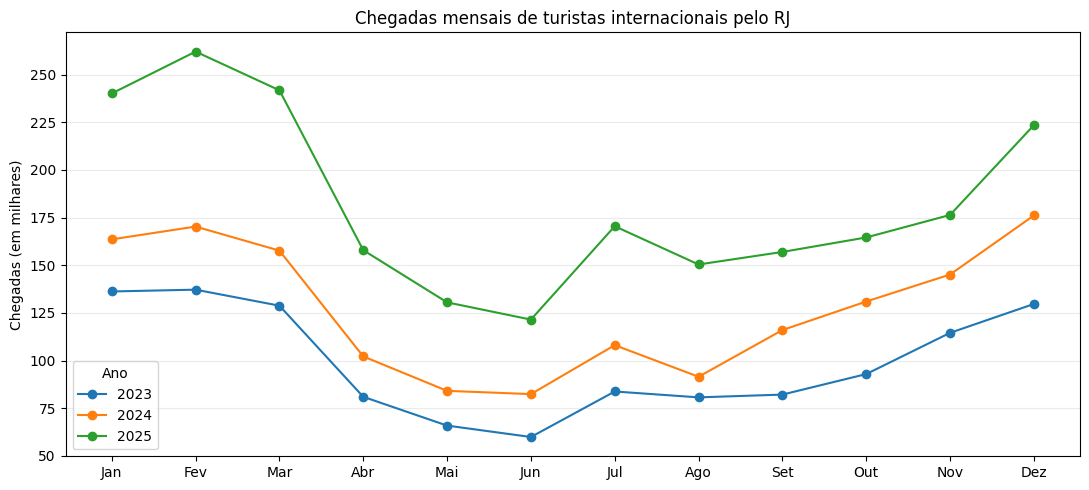

,Mês com mais chegadas,Chegadas no mês
Ano,,
2023,Fevereiro,137200
2024,Dezembro,176121
2025,Fevereiro,262108


In [16]:
# @title Texto de título padrão
fig, ax = plt.subplots(figsize=(11, 5))
picos_mensais = []

for ano, totais in sorted(totais_mensais.items()):
    ax.plot(range(12), totais / 1_000, marker="o", label=str(ano))

    mes_pico = totais.idxmax()
    picos_mensais.append({
        "Ano": ano,
        "Mês com mais chegadas": mes_pico.capitalize(),
        "Chegadas no mês": int(totais.loc[mes_pico]),
    })

ax.set_title("Chegadas mensais de turistas internacionais pelo RJ")
ax.set_xticks(
    range(12),
    ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
     "Jul", "Ago", "Set", "Out", "Nov", "Dez"],
)
ax.set_ylabel("Chegadas (em milhares)")
ax.legend(title="Ano")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

display(pd.DataFrame(picos_mensais).set_index("Ano"))

### Figura 1 — Chegadas mensais de turistas internacionais pelo RJ (2023–2025)

O gráfico de linhas permite comparar os mesmos meses nos três anos e identificar quando ocorreram os picos de chegadas, conforme a H1.

**Achado:** Fevereiro foi o mês com mais chegadas internacionais pelo Rio de Janeiro em dois dos três anos analisados. Junho teve o menor volume mensal nos três anos.

**Evidência:** Em 2023, o pico ocorreu em fevereiro, com 137.200 chegadas. Em 2024, ocorreu em dezembro, com 176.121 chegadas. Em 2025, voltou a ocorrer em fevereiro, com 262.108 chegadas.

**Relação com H1/H2 e limite:** A figura responde à primeira parte da H1 ao identificar o mês de maior movimento em cada ano. O período de três anos permite descrever o padrão observado no recorte. Para saber quais países de residência mais contribuíram para cada pico, é preciso detalhar as chegadas desses três meses por país.

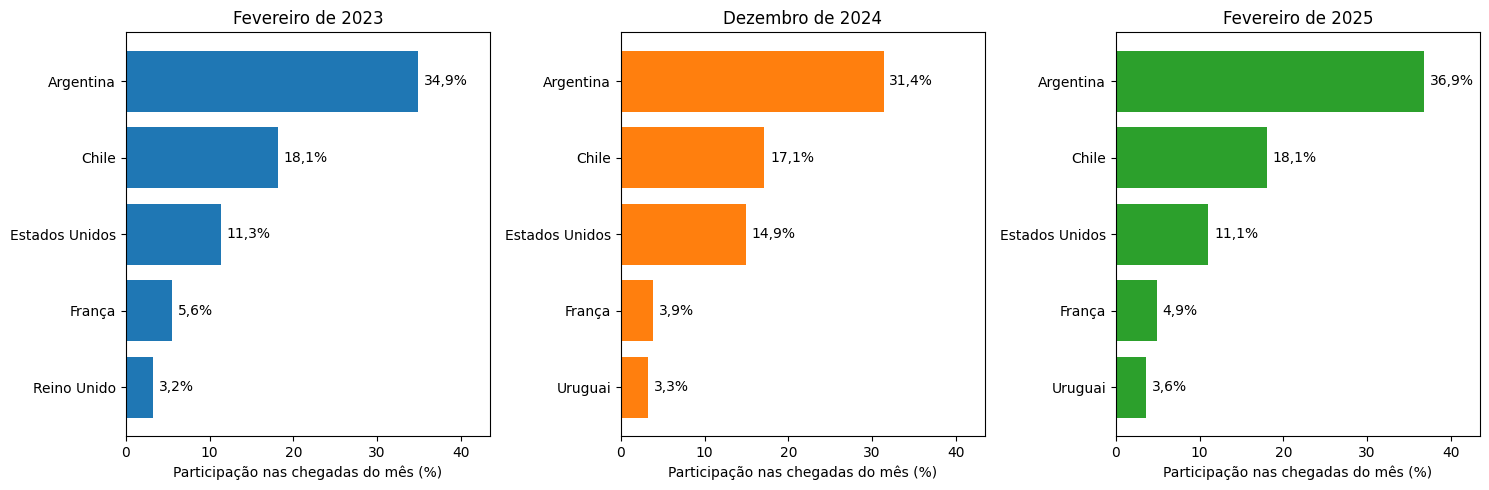

Chegadas  Participação no mês (%)
Mês de pico       País de residência                                   
Fevereiro de 2023 Argentina              47944                    34.94
                  Chile                  24853                    18.11
                  Estados Unidos         15515                    11.31
                  França                  7626                     5.56
                  Reino Unido             4433                     3.23
Dezembro de 2024  Argentina              55262                    31.38
                  Chile                  30195                    17.14
                  Estados Unidos         26320                    14.94
                  França                  6815                     3.87
                  Uruguai                 5814                      3.3
Fevereiro de 2025 Argentina              96599                    36.85
                  Chile                  47312                    18.05
                  Estados Unidos         28998                    11.06
                  França                 12955                     4.94
                  Uruguai                 9547                     3.64

In [17]:
# @title Texto de título padrão
fig, eixos = plt.subplots(1, 3, figsize=(15, 5), sharex=True)
paises_nos_picos = {}

for indice, (ax, (ano, dados)) in enumerate(zip(eixos, sorted(dados_rj.items()))):
    mes_pico = totais_mensais[ano].idxmax()

    coluna_mes = colunas_por_ano["Mês"][ano]
    mes = (
        dados[coluna_mes]
        .str.strip()
        .str.casefold()
        .replace({"marco": "março"})
    )

    dados_pico = dados.loc[mes.eq(mes_pico)]
    coluna_pais = colunas_por_ano["País de residência"][ano]
    pais = dados_pico[coluna_pais].str.strip()
    chegadas = pd.to_numeric(dados_pico["Chegadas"].str.strip())
    por_pais = chegadas.groupby(pais).sum()

    paises_individuais = por_pais.loc[
        ~por_pais.index.str.startswith("Outros países")
    ]
    cinco_maiores = paises_individuais.nlargest(5).to_frame("Chegadas")
    cinco_maiores["Participação no mês (%)"] = (
        100 * cinco_maiores["Chegadas"] / chegadas.sum()
    )

    periodo = f"{mes_pico.capitalize()} de {ano}"
    paises_nos_picos[periodo] = cinco_maiores

    participacao = cinco_maiores["Participação no mês (%)"]
    barras = ax.barh(cinco_maiores.index, participacao, color=f"C{indice}")
    ax.bar_label(
        barras,
        labels=[f"{valor:.1f}%".replace(".", ",") for valor in participacao],
        padding=4,
    )
    ax.invert_yaxis()
    ax.set_title(periodo)
    ax.set_xlabel("Participação nas chegadas do mês (%)")
    ax.margins(x=0.18)

fig.tight_layout()
plt.show()

display(pd.concat(paises_nos_picos, names=["Mês de pico", "País de residência"]).round(2))

###Figura 2 — Principais países de residência nos meses de pico

O gráfico de barras compara os cinco países de residência com mais chegadas em cada mês de pico. Cada percentual é calculado sobre o total de chegadas daquele mês pelo Rio de Janeiro, considerando as duas vias de entrada e as categorias agrupadas da fonte.

**Achado:** Argentina, Chile e Estados Unidos foram, nessa ordem, os três países de residência com mais chegadas pelo Rio de Janeiro nos três meses de pico analisados.

**Evidência:** A Argentina respondeu por 34,94% das chegadas em fevereiro de 2023, 31,38% em dezembro de 2024 e 36,85% em fevereiro de 2025. Nesse último pico, foram registradas 96.599 chegadas de residentes na Argentina.

**Relação com H1 e limite:** A figura responde à segunda parte da H1 ao identificar os países de residência que mais contribuíram para o volume de chegadas em cada pico. Como o pico de 2024 ocorreu em dezembro e os demais em fevereiro, a comparação descreve a composição dos picos. Para avaliar mudanças na participação de cada país entre anos, seria preciso comparar o mesmo mês.

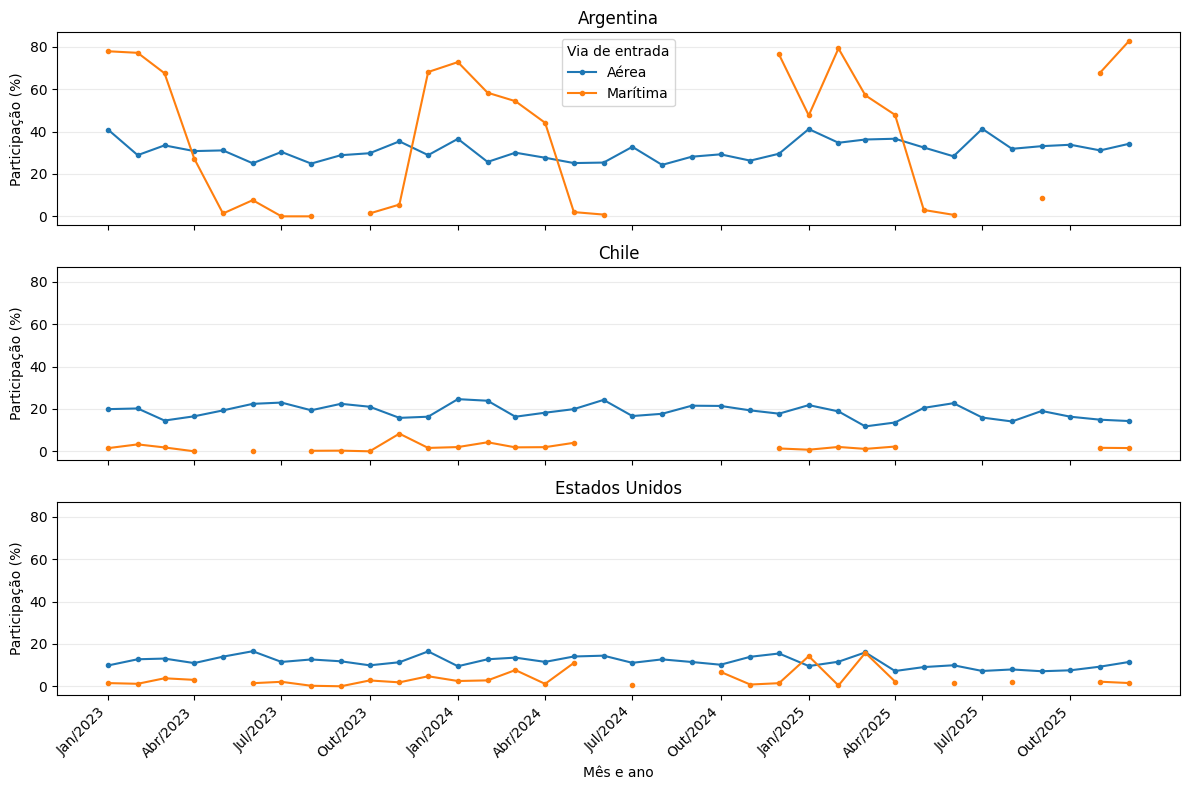

Conferência dos percentuais — fevereiro de 2025


Chegadas  Total da via no mês  Participação (%)
País           Via                                                      
Argentina      Aérea        86771               249713             34.75
               Marítima      9828                12395             79.29
Chile          Aérea        47057               249713             18.84
               Marítima       255                12395              2.06
Estados Unidos Aérea        28952               249713             11.59
               Marítima        46                12395              0.37

In [18]:
# @title Texto de título padrão
paises_h2 = ["Argentina", "Chile", "Estados Unidos"]
vias_h2 = ["Aérea", "Marítima"]
numero_mes = {nome: numero for numero, nome in enumerate(meses, start=1)}
partes_h2 = []

for ano, dados in sorted(dados_rj.items()):
    mes = (
        dados[colunas_por_ano["Mês"][ano]]
        .str.strip()
        .str.casefold()
        .replace({"marco": "março"})
        .map(numero_mes)
    )
    via = (
        dados[colunas_por_ano["Via de entrada"][ano]]
        .str.strip()
        .replace({"Aéreo": "Aérea", "Marítimo": "Marítima"})
    )

    partes_h2.append(pd.DataFrame({
        "Período": pd.to_datetime({"year": ano, "month": mes, "day": 1}),
        "Via": via,
        "País": dados[colunas_por_ano["País de residência"][ano]].str.strip(),
        "Chegadas": pd.to_numeric(dados["Chegadas"].str.strip()),
    }))

base_h2 = pd.concat(partes_h2, ignore_index=True)
perfil_h2 = (
    base_h2.groupby(["Período", "Via", "País"], as_index=False)["Chegadas"]
    .sum()
)
total_via = perfil_h2.groupby(["Período", "Via"])["Chegadas"].transform("sum")
perfil_h2["Participação (%)"] = (
    100 * perfil_h2["Chegadas"] / total_via.where(total_via.gt(0))
)

periodos = pd.date_range("2023-01-01", "2025-12-01", freq="MS")
fig, eixos = plt.subplots(3, 1, figsize=(12, 8), sharex=True, sharey=True)

for ax, pais in zip(eixos, paises_h2):
    serie = (
        perfil_h2.loc[perfil_h2["País"].eq(pais)]
        .pivot(index="Período", columns="Via", values="Participação (%)")
        .reindex(index=periodos, columns=vias_h2)
    )

    for via in vias_h2:
        ax.plot(serie.index, serie[via], marker="o", markersize=3, label=via)

    ax.set_title(pais)
    ax.set_ylabel("Participação (%)")
    ax.grid(axis="y", alpha=0.25)

eixos[0].legend(title="Via de entrada")
eixos[-1].set_xlabel("Mês e ano")
marcas = periodos[::3]
rotulos = [
    f"{meses[data.month - 1][:3].capitalize()}/{data.year}"
    for data in marcas
]
eixos[-1].set_xticks(marcas, rotulos, rotation=45, ha="right")
fig.tight_layout()
plt.show()

mes_conferencia = pd.Timestamp("2025-02-01")
dados_mes = perfil_h2.loc[perfil_h2["Período"].eq(mes_conferencia)]
totais_por_via = dados_mes.groupby("Via")["Chegadas"].sum()

pares = pd.MultiIndex.from_product(
    [paises_h2, vias_h2],
    names=["País", "Via"],
)

conferencia = (
    dados_mes.set_index(["País", "Via"])[["Chegadas", "Participação (%)"]]
    .reindex(pares)
)
conferencia["Total da via no mês"] = (
    conferencia.index.get_level_values("Via").map(totais_por_via)
)

print("Conferência dos percentuais — fevereiro de 2025")
display(conferencia[[
    "Chegadas", "Total da via no mês", "Participação (%)"
]].round(2))

###Figura 3 — Participação dos principais países de residência por via de entrada

Os três painéis mostram a participação mensal de Argentina, Chile e Estados Unidos nas chegadas pelo Rio de Janeiro. Para cada país, a participação é calculada sobre o total de chegadas da respectiva via no mesmo mês e ano. Os painéis usam a mesma escala para facilitar a comparação.

**Achado:** Entre 2023 e 2025, a participação da Argentina oscilou mais na via marítima do que na aérea. Em fevereiro de 2025, a Argentina teve maior participação na via marítima, enquanto Chile e Estados Unidos tiveram maior participação na via aérea.

**Evidência:** Em fevereiro de 2025, residentes na Argentina representaram **79,29% das chegadas marítimas** e **34,75% das aéreas**, uma diferença de **44,54 pontos percentuais**. Em volume, foram **9.828 chegadas por mar** e **86.771 por ar**.

**Relação com H2 e limite:** A comparação mostra como o perfil por país de residência pode variar entre as duas vias em um mesmo mês. Em fevereiro de 2025, os percentuais foram calculados sobre **12.395 chegadas marítimas** e **249.713 aéreas**. Como os totais das vias são diferentes, uma participação maior pode corresponder a um volume menor de chegadas. O exemplo descreve fevereiro de 2025, e o gráfico permite acompanhar como essas diferenças variaram nos demais meses.

# 5. Pré-processamento e decisões

## 5.1 Plano e prevenção de vazamento

O pré-processamento parte dos três CSVs nacionais, armazenados em `dados_originais`, e do recorte do Rio de Janeiro, armazenado em `dados_rj`. A base preparada terá uma linha por combinação de ano, mês, país de residência e via de entrada. A preparação inclui padronizar os rótulos de mês e via, converter `Chegadas` para inteiro e somar as chegadas por combinação. A soma anual será conferida após a agregação para verificar se o volume de chegadas foi preservado.

Como o objetivo é descrever as chegadas registradas de 2023 a 2025, a análise utiliza todo o período. A divisão em conjuntos de treino e teste é **não aplicável**.

In [19]:
base_padronizada = pd.DataFrame({
    "uf_entrada": "Rio de Janeiro",
    "ano": base_h2["Período"].dt.year,
    "mes": base_h2["Período"].dt.month,
    "pais_residencia": base_h2["País"],
    "via_entrada": base_h2["Via"],
    "chegadas": base_h2["Chegadas"],
})

chave = ["uf_entrada", "ano", "mes", "pais_residencia", "via_entrada"]

if base_padronizada[chave].isna().any().any():
    raise ValueError("Há campos ausentes na chave de agregação.")

base_preparada = (
    base_padronizada.groupby(chave, as_index=False)["chegadas"]
    .sum()
)

conferencia_base = pd.DataFrame({
    "Linhas antes": pd.Series({
        ano: len(dados) for ano, dados in dados_rj.items()
    }),
    "Linhas depois": base_preparada.groupby("ano").size(),
    "Chegadas antes": pd.Series({
        ano: pd.to_numeric(dados["Chegadas"].str.strip()).sum()
        for ano, dados in dados_rj.items()
    }),
    "Chegadas depois": base_preparada.groupby("ano")["chegadas"].sum(),
})

conferencia_base["Diferença nas chegadas"] = (
    conferencia_base["Chegadas depois"] - conferencia_base["Chegadas antes"]
)

display(conferencia_base.rename_axis("Ano"))

,Linhas antes,Linhas depois,Chegadas antes,Chegadas depois,Diferença nas chegadas
Ano,,,,,
2023,3140,1521,1192814,1192814,0
2024,2349,1512,1528133,1528133,0
2025,2407,2315,2196443,2196443,0


Após a agregação, a base passou de 7.896 para 5.348 linhas, distribuídas em 1.521 em 2023, 1.512 em 2024 e 2.315 em 2025. Cada linha da base preparada representa uma combinação de ano, mês, país de residência e via de entrada. A diferença entre os totais de chegadas antes e depois da agregação foi zero nos três anos.

## 5.2 D1 — Padronização dos rótulos de mês e via

**Necessidade e evidência:** A checagem da seção 4.1 mostrou que o arquivo de 2023 usava `Marco`, `Aéreo` e `Marítimo`. Nos arquivos de 2024 e 2025, os rótulos correspondentes eram `Março`, `Aérea` e `Marítima`. Essas variações poderiam criar categorias separadas ao reunir os três anos.

**Alternativas:** Manter os rótulos de origem e tratar as equivalências em cada análise, ou aplicar um mapeamento explícito na preparação da base.

**Escolha e justificativa:** Foi adotado o mapeamento explícito das grafias observadas. O mês foi convertido para um número de 1 a 12, de modo a permitir a ordenação cronológica, e as vias foram padronizadas como `Aérea` e `Marítima`.

In [20]:
checagem_rotulos = base_padronizada.groupby("ano").agg(
    meses_distintos=("mes", "nunique"),
    vias_observadas=("via_entrada", lambda via: ", ".join(sorted(via.unique()))),
)

display(checagem_rotulos)

,meses_distintos,vias_observadas
ano,,
2023,12,"Aérea, Marítima"
2024,12,"Aérea, Marítima"
2025,12,"Aérea, Marítima"


**Resultado e validação:** Após a padronização, a conferência identificou 12 meses distintos em cada ano e duas categorias de via de entrada, `Aérea` e `Marítima`. As grafias `Aéreo` e `Marítimo` do arquivo de 2023 passaram a usar os mesmos rótulos dos arquivos de 2024 e 2025.

**Limitação:** O mapeamento foi definido a partir das grafias observadas nos arquivos de 2023 a 2025. Se novos arquivos forem incorporados, será necessário conferir se trazem outros rótulos para mês ou via de entrada.

## 5.3 D2 — Tratamento das linhas idênticas

**Necessidade e evidência:** A seção 4.1 identificou ocorrências adicionais de linhas idênticas com valores positivos em `Chegadas`. Excluir essas ocorrências altera o volume anual de chegadas pelo Rio de Janeiro.

**Alternativas:** Preservar todas as linhas publicadas ou manter apenas a primeira ocorrência de cada linha idêntica.

**Escolha e justificativa:** Foram preservadas todas as linhas na soma, pois esse cenário reproduz os totais anuais publicados pelo Ministério do Turismo e pela Embratur, referenciados na seção 4.1.

In [21]:
conferencia_d2 = pd.DataFrame(comparacao_totais).set_index("Ano")
conferencia_d2["Total oficial"] = pd.Series({
    2023: 1_192_814,
    2024: 1_528_133,
    2025: 2_196_443,
})

conferencia_d2["Diferença com todas as linhas"] = (
    conferencia_d2["Total com todas as linhas"] - conferencia_d2["Total oficial"]
)
conferencia_d2["Diferença sem repetições"] = (
    conferencia_d2["Total sem repetições idênticas"] - conferencia_d2["Total oficial"]
)

display(conferencia_d2[[
    "Total oficial",
    "Diferença com todas as linhas",
    "Diferença sem repetições",
]])

,Total oficial,Diferença com todas as linhas,Diferença sem repetições
Ano,,,
2023,1192814,0,-683
2024,1528133,0,-937
2025,2196443,0,-19


**Resultado e validação:** A soma com todas as linhas reproduziu os totais oficiais de chegadas pelo Rio de Janeiro em 2023, 2024 e 2025. Ao excluir as ocorrências adicionais de linhas idênticas, a soma ficou abaixo da referência em **683 chegadas em 2023**, **937 em 2024** e **19 em 2025**. Com base nessa comparação, todas as linhas foram mantidas no cálculo.

**Limitação:** A concordância com os totais oficiais foi verificada no nível anual. A origem das repetições e a validade de cada ocorrência individual permanecem em aberto.

## 5.4 D3 — Agregação das chegadas

**Necessidade e evidência:** A conferência da seção 5.1 mostrou que uma mesma combinação de ano, mês, país de residência e via de entrada podia aparecer em várias linhas do recorte do Rio de Janeiro.

**Alternativas:** Manter as linhas no nível original e somar as chegadas a cada análise, ou preparar uma base com uma linha por combinação.

**Escolha e justificativa:** As chegadas foram somadas por UF de entrada, ano, mês, país de residência e via de entrada. Essa estrutura permite calcular os totais mensais da H1 e as participações por país e via da H2 a partir da mesma base.

In [22]:
display(conferencia_base.rename_axis("Ano"))

chaves_repetidas = base_preparada.duplicated(subset=chave).sum()
print(f"Linhas adicionais com a mesma chave: {chaves_repetidas}")

,Linhas antes,Linhas depois,Chegadas antes,Chegadas depois,Diferença nas chegadas
Ano,,,,,
2023,3140,1521,1192814,1192814,0
2024,2349,1512,1528133,1528133,0
2025,2407,2315,2196443,2196443,0


Linhas adicionais com a mesma chave: 0


**Resultado e validação:** A agregação reduziu a base de **7.896 para 5.348 linhas**. Cada combinação da chave aparece uma única vez na base preparada, e a soma das chegadas foi preservada em cada ano.

**Limitação:** A agregação cobre as combinações presentes nos arquivos. As combinações ausentes continuam sem registro, e categorias agrupadas como `Outros países` permanecem com o nível de detalhe publicado pela fonte.

## 5.5 Estado final dos dados

O notebook mantém os três arquivos nacionais em `dados_originais`, o recorte do Rio de Janeiro por ano em `dados_rj` e a base agregada em `base_preparada`. A base preparada contém **5.348 linhas e 6 colunas**. Cada linha representa uma combinação de UF de entrada, ano, mês, país de residência e via de entrada, com o respectivo total de chegadas.

Os meses foram representados por números de 1 a 12, e as vias foram padronizadas como `Aérea` e `Marítima`. A agregação preservou os totais anuais, e a checagem da D3 confirmou que cada combinação da chave aparece uma única vez. A base preparada pode ser recriada executando o notebook desde a leitura dos CSVs na [pasta `dados/` do GitHub](https://github.com/Silvinharl/MVP_Analise_de_dados/tree/main/dados).

In [23]:
linhas, colunas = base_preparada.shape
print(f"Dimensões da base preparada: {linhas} linhas × {colunas} colunas")

checagem_final = pd.DataFrame({
    "Tipo": base_preparada.dtypes.astype(str),
    "Valores ausentes": base_preparada.isna().sum(),
})

display(checagem_final)
display(base_preparada.head())

Dimensões da base preparada: 5348 linhas × 6 colunas


,Tipo,Valores ausentes
uf_entrada,object,0
ano,int32,0
mes,int32,0
pais_residencia,string,0
via_entrada,string,0
chegadas,Int64,0


,uf_entrada,ano,mes,pais_residencia,via_entrada,chegadas
0,Rio de Janeiro,2023,1,Alemanha,Aérea,2527
1,Rio de Janeiro,2023,1,Alemanha,Marítima,23
2,Rio de Janeiro,2023,1,Angola,Aérea,13
3,Rio de Janeiro,2023,1,Argentina,Aérea,48727
4,Rio de Janeiro,2023,1,Argentina,Marítima,13568


# 6. Respostas e conclusão

#### Síntese das respostas a H1 e H2

| Pergunta | Evidência e localização | Limitação |
|:---|:---|:---|
| **H1 — Quando ocorreram os picos**<br>**e quais países mais contribuíram?** | **Figuras 1 e 2**<br><br>**2023** · Fevereiro · 137.200 chegadas<br><br>**2024** · Dezembro · 176.121 chegadas<br><br>**2025** · Fevereiro · 262.108 chegadas<br><br>Argentina, Chile e Estados Unidos<br>lideraram os três picos, nessa ordem. | A comparação reúne meses de pico diferentes.<br><br>O padrão observado se refere aos três anos<br>da série. |
| **H2 — Como a composição por país**<br>**varia entre as vias no mesmo mês e ano?** | **Figura 3 · Fevereiro de 2025**<br><br>**Argentina** · 79,29% por mar e 34,75% por ar<br><br>**Chile** · 2,06% por mar e 18,84% por ar<br><br>**Estados Unidos** · 0,37% por mar e 11,59% por ar | Cada percentual usa o total da própria via.<br><br>Fevereiro de 2025 é um exemplo da série.<br><br>As lacunas indicam ausência de registro. |

Entre 2023 e 2025, o número anual de chegadas de turistas internacionais pelo Rio de Janeiro passou de 1,19 milhão para 2,20 milhões. Fevereiro foi o mês de maior movimento em 2023 e 2025, e dezembro foi o pico em 2024. Nos três picos, Argentina, Chile e Estados Unidos foram, nessa ordem, os países de residência com mais chegadas. A composição também variou por via de entrada. Em fevereiro de 2025, residentes na Argentina representaram 79,29% das chegadas marítimas e 34,75% das aéreas. Em volume, foram 9.828 chegadas por mar e 86.771 por ar, o que mostra por que é importante ler os percentuais junto com as contagens.

A análise descreve as entradas no Brasil pelo estado do Rio de Janeiro. O destino final dos turistas fica fora do alcance da base. Na comparação entre vias, as lacunas indicam combinações de país, mês e via sem registro no arquivo. Como próximo passo, uma série histórica mais longa permitiria verificar se fevereiro e dezembro aparecem com frequência entre os meses de maior movimento.

#### Declaração do uso de IA

Usei o ChatGPT como apoio na elaboração e revisão do código Python, na construção de tabelas e gráficos e na revisão da redação das explicações metodológicas.  Os resultados numéricos foram obtidos pela execução do código no Google Colab, a partir dos arquivos do Ministério do Turismo.

# 7. Checklist de entrega

| Item | Localização no notebook | Não aplicabilidade, se houver |
|:---|:---|:---|
| 1. Problema, unidade, perguntas e objetivo | Seções 1.1 e 1.2 | — |
| 2. Fonte, período, recortes e dicionário | Seções 2.1 e 2.2 | — |
| 3. Dimensões, tipos e estatísticas | Seções 3, 4.2 e 5.5 | — |
| 4. Ausências, duplicidades, inconsistências e extremos | Seções 4.1 e 4.2 | — |
| 5. Distribuições, relações e classes, quando aplicável | Seções 4.2 e 4.3 | Classes não aplicáveis à análise descritiva. |
| 6. Interpretações das figuras | Seção 4.3, abaixo das Figuras 1 a 3 | — |
| 7. D1–D3 e comparação de alternativas | Seções 5.2 a 5.4. Comparação na D2 (5.3). | — |
| 8. Transformações ou manutenção e verificações | Seções 5.1 a 5.5 | — |
| 9. Prevenção de vazamento ou não aplicabilidade | Seção 5.1 | Divisão em treino e teste não aplicável à análise descritiva. |
| 10. Conclusão, limites e próximos passos | Seção 6 | — |
| 11. Referências e declaração de IA | Fontes nas seções 2.1 e 4.1. Declaração de IA ao fim da seção 6. | — |
| 12. Finalização, execução, dados e link do Colab | Execução completa em sessão nova confirmada. Carregamento dos dados na seção 3. Link do Colab no cabeçalho | — |